<a href="https://colab.research.google.com/github/sergiomorapardo/StochasticAITechniquesClass/blob/main/Notebooks/L4b_Regularization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 # Notebook: Regresión Lineal (Parte 2): Overfitting, Regularización y Selección de Variables

 Este notebook continúa la **Parte 1: [L4: Regresión Lineal](L4_LinearRegression.ipynb)**, donde construimos un modelo lineal base para predecir `mpg` (dataset "Auto MPG"), evaluamos la significancia de sus coeficientes, comprobamos sus supuestos y comparamos modelos con AIC y BIC.

 **¿Dónde quedamos?** El modelo base tiene un buen ajuste (R² ≈ 0.82), pero sus residuales muestran una "U": la relación entre `mpg` y variables como `weight` u `horsepower` **no es lineal**.

 En esta Parte 2 veremos:

 1.  Diagnóstico del modelo (Overfitting) usando características polinómicas.
 2.  **R² ajustado** y grados de libertad efectivos para medir la complejidad de cada modelo.
 3.  **Solución 1: Regularización (Ridge, Lasso, Elastic-Net).**
 4.  **Solución 2: Sintonización de Hiperparámetros (CV y GridSearch).**
 5.  **Solución 3: Selección de Variables (Stepwise).**
 6.  Comparación final de todos los modelos.

 > ⏱️ **Nota:** las secciones 8 y 9 (CV y GridSearch sobre 2001 variables polinómicas) pueden tardar varios minutos en ejecutarse.

 ## Preparación (repaso de la Parte 1)

 Para que este notebook pueda ejecutarse por sí solo, repetimos los pasos de la Parte 1 que necesitamos: importaciones, carga de datos, división Train/Test, pipeline de preprocesamiento y modelo lineal base. Las explicaciones detalladas están en la [Parte 1](L4_LinearRegression.ipynb).

In [1]:
# Importaciones principales
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocesamiento de sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Modelos Lineales
from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso,
    ElasticNet,
    RidgeCV,
    LassoCV,
    ElasticNetCV
)

# Selección de variables y Sintonización
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.model_selection import GridSearchCV

# Métricas y Visualización
from sklearn.metrics import mean_squared_error, PredictionErrorDisplay

# Configuración de visualización
plt.style.use('ggplot')
pd.set_option('display.max_columns', None)


In [2]:
# Cargar el dataset directamente desde Seaborn (alternativa a UCI)
try:
    df = sns.load_dataset('mpg')
    print("Dataset 'mpg' cargado exitosamente.")
except Exception as e:
    print(f"Error cargando el dataset: {e}")
    print("Intentando cargar desde UCI...")
    # URL del dataset original
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"
    # Nombres de las columnas
    column_names = ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight',
                    'acceleration', 'model_year', 'origin', 'name']
    # Leer los datos, especificando el separador (espacio) y los valores faltantes (?)
    df = pd.read_csv(url, names=column_names, delim_whitespace=True, na_values="?")


print(f"Tamaño del dataset: {df.shape}")
df.head()


Dataset 'mpg' cargado exitosamente.
Tamaño del dataset: (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [ ]:
# Como en la Parte 1: 'name' (nombre del auto) no es una variable predictiva
df = df.drop(columns=['name'])

In [5]:
X = df.drop(columns=['mpg'])
y = df['mpg']

# Dividimos 80% entrenamiento, 20% prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Tamaño de Entrenamiento: {X_train.shape}")
print(f"Tamaño de Prueba: {X_test.shape}")


Tamaño de Entrenamiento: (318, 7)
Tamaño de Prueba: (80, 7)


In [7]:
# 1. Definir las listas de columnas
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(include='object').columns.tolist()

print(f"Columnas numéricas: {numeric_features}")
print(f"Columnas categóricas: {categorical_features}")

# 2. Crear el pipeline para variables numéricas
#    - Paso 1: Imputar valores faltantes (NaN) con la media
#    - Paso 2: Escalar los datos (StandardScaler)
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

# 3. Crear el pipeline para variables categóricas
#    - Paso 1: Convertir a One-Hot Encoding
categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# 4. Combinar ambos pipelines en un ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='passthrough' # Mantiene columnas no especificadas (si las hubiera)
)


Columnas numéricas: ['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year']
Columnas categóricas: ['origin']


In [8]:
# Creamos el pipeline final que incluye el preprocesamiento Y el modelo
model_pipeline_base = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

# Entrenamos el modelo
model_pipeline_base.fit(X_train, y_train)

# Predecimos en el set de prueba
y_pred_base_train = model_pipeline_base.predict(X_train)
y_pred_base = model_pipeline_base.predict(X_test)

# Calculamos el RMSE (Root Mean Squared Error)
# Usamos np.sqrt() porque mean_squared_error da el MSE
rmse_base_train = np.sqrt(mean_squared_error(y_train, y_pred_base_train))
rmse_base = np.sqrt(mean_squared_error(y_test, y_pred_base))

print(f"RMSE del Modelo Base: {rmse_base_train:.4f}")
print(f"RMSE del Modelo Base: {rmse_base:.4f}")

# Lista para guardar los resultados de todos los modelos
results = []
results.append({'Modelo': '1. Lineal Base', 'RMSE_Test': rmse_base})


RMSE del Modelo Base: 3.3702
RMSE del Modelo Base: 2.8877


 ## 5. El Problema: Creando Overfitting



 ¿Cómo podemos capturar la "curva" que vimos? Usando `PolynomialFeatures`.



 Pero esto es peligroso. Un polinomio de grado alto (ej. grado 3) creará muchísimas variables nuevas (interacciones como $peso \times potencia$, $peso^2$, $potencia^3$, etc.), llevando a un **sobreajuste (overfitting)**.



 **Overfitting:** El modelo memoriza los datos de entrenamiento (RMSE de entrenamiento muy bajo) pero falla miserablemente al predecir datos nuevos (RMSE de prueba muy alto).

 ### R² Ajustado: penalizando la complejidad

A partir de aquí, además de MSE, RMSE y R², reportamos el **R² ajustado** para cada modelo en Train y Test:

$$R^2_{adj} = 1 - (1 - R^2)\,\frac{n - 1}{n - p - 1}$$

donde $n$ es el número de observaciones y $p$ el número de parámetros (sin contar el intercepto).

* El $R^2$ **siempre sube** (o se queda igual) al agregar variables, aunque sean ruido. El $R^2$ ajustado **castiga** cada parámetro extra: solo sube si la nueva variable aporta más de lo que "cuesta".
* Si $p \geq n - 1$, el denominador es $\leq 0$ y el $R^2$ ajustado **no está definido** (lo reportamos como `NaN`). ¡Es justo lo que pasa con el modelo polinómico de grado 5, que tiene 2001 variables y solo 318 observaciones!

**¿Cuánto vale $p$ en un modelo regularizado?** En Ridge/Lasso los coeficientes están "encogidos", así que contar columnas exagera la complejidad real. Usamos los **grados de libertad efectivos**:

* **OLS:** el rango de la matriz de diseño (número de columnas linealmente independientes).
* **Ridge:** $p_{ef} = \sum_j \frac{d_j^2}{d_j^2 + \alpha}$, donde $d_j$ son los valores singulares de $X$ centrada. Con $\alpha = 0$ vuelve a ser el rango; con $\alpha \to \infty$ tiende a 0.
* **Lasso:** el número de coeficientes distintos de cero (Zou, Hastie y Tibshirani, 2007).
* **ElasticNet:** la fórmula de Ridge aplicada solo a las variables activas (las de coeficiente $\neq 0$), con la penalización L2 del modelo.

*Nota: el ajuste del $R^2$ es, en rigor, un concepto de entrenamiento (castiga la complejidad con la que se ajustó el modelo). En Test lo calculamos con el mismo $p$ y el $n$ de Test solo como referencia.*

In [18]:
from sklearn.metrics import r2_score
from scipy import sparse

def effective_params(model, X_proc):
    """Grados de libertad efectivos del modelo (sin contar el intercepto)."""
    X_proc = X_proc.toarray() if sparse.issparse(X_proc) else np.asarray(X_proc, dtype=float)
    Xc = X_proc - X_proc.mean(axis=0)  # sklearn centra X al ajustar el intercepto
    n = Xc.shape[0]
    coef = np.ravel(model.coef_)

    if isinstance(model, (Ridge, RidgeCV)):
        alpha_m = model.alpha_ if hasattr(model, 'alpha_') else model.alpha
        d = np.linalg.svd(Xc, compute_uv=False)
        return float(np.sum(d**2 / (d**2 + alpha_m)))

    if isinstance(model, (ElasticNet, LassoCV, ElasticNetCV)):  # Lasso es una subclase de ElasticNet
        alpha_m = model.alpha_ if hasattr(model, 'alpha_') else model.alpha
        l1 = getattr(model, 'l1_ratio_', getattr(model, 'l1_ratio', 1.0))
        activas = np.flatnonzero(coef)
        # sklearn minimiza (1/2n)||y - Xw||^2 + alpha*l1*||w||_1 + 0.5*alpha*(1-l1)*||w||^2
        lambda_2 = n * alpha_m * (1 - l1)
        if len(activas) == 0 or lambda_2 == 0:
            return float(len(activas))
        d = np.linalg.svd(Xc[:, activas], compute_uv=False)
        return float(np.sum(d**2 / (d**2 + lambda_2)))

    # OLS (LinearRegression): rango de la matriz de diseño
    return float(np.linalg.matrix_rank(Xc))


def regression_report(nombre, model, X_tr, y_tr, X_te, y_te):
    """Muestra MSE, RMSE, R2 y R2 ajustado en Train y Test, y devuelve una fila para la tabla final."""
    if isinstance(model, Pipeline):
        p = effective_params(model.steps[-1][1], model[:-1].transform(X_tr))
    else:
        p = effective_params(model, X_tr)

    filas = {}
    for split, X_, y_ in [('Train', X_tr, y_tr), ('Test', X_te, y_te)]:
        y_hat = model.predict(X_)
        n = len(y_)
        mse = mean_squared_error(y_, y_hat)
        r2 = r2_score(y_, y_hat)
        r2_adj = 1 - (1 - r2) * (n - 1) / (n - p - 1) if n - p - 1 > 0 else np.nan
        filas[split] = {'MSE': mse, 'RMSE': np.sqrt(mse), 'R2': r2, 'R2 Ajustado': r2_adj}

    tabla = pd.DataFrame(filas).T
    print(f"{nombre} | parámetros efectivos p = {p:.1f}")
    display(tabla.round(4))

    return {'Modelo': nombre, 'p efectivo': p,
            'RMSE Train': filas['Train']['RMSE'], 'RMSE Test': filas['Test']['RMSE'],
            'R2 Train': filas['Train']['R2'], 'R2 Test': filas['Test']['R2'],
            'R2 Ajustado Train': filas['Train']['R2 Ajustado'], 'R2 Ajustado Test': filas['Test']['R2 Ajustado']}


# Lista con las métricas completas de cada modelo (complementa a `results`)
metrics_results = []

# Punto de referencia: el Modelo Base
metrics_results.append(regression_report('1. Lineal Base', model_pipeline_base, X_train, y_train, X_test, y_test))

1. Lineal Base | parámetros efectivos p = 8.0


,MSE,RMSE,R2,R2 Ajustado
Train,11.3584,3.3702,0.8188,0.8141
Test,8.3390,2.8877,0.8449,0.8274


In [12]:
# Definimos un pipeline polinómico
pipe_poly_overfit = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('poly_features', PolynomialFeatures(degree=5, include_bias=False)),
    ('model', LinearRegression())
])

# Entrenamos el modelo sobreajustado
pipe_poly_overfit.fit(X_train, y_train)

# Evaluamos en Train
y_pred_poly_overfit_train = pipe_poly_overfit.predict(X_train)
rmse_poly_overfit_train = np.sqrt(mean_squared_error(y_train, y_pred_poly_overfit_train))

print(f"RMSE Modelo Polinómico (Grado 5) en Train: {rmse_poly_overfit_train:.4f}")

# Evaluamos en Test
y_pred_poly_overfit = pipe_poly_overfit.predict(X_test)
rmse_poly_overfit = np.sqrt(mean_squared_error(y_test, y_pred_poly_overfit))


print(f"RMSE Modelo Polinómico (Grado 5) en Test: {rmse_poly_overfit:.4f}")
results.append({'Modelo': '2. Polinómico (Overfit)', 'RMSE_Test': rmse_poly_overfit})


RMSE Modelo Polinómico (Grado 5) en Train: 0.0000
RMSE Modelo Polinómico (Grado 5) en Test: 80.9767


In [20]:
# Métricas completas en Train y Test (incluye R2 ajustado)
metrics_results.append(regression_report('2. Polinómico (Overfit)', pipe_poly_overfit, X_train, y_train, X_test, y_test))

2. Polinómico (Overfit) | parámetros efectivos p = 317.0


,MSE,RMSE,R2,R2 Ajustado
Train,0.0000,0.0000,1.0000,NaN
Test,6557.2327,80.9767,-120.9577,NaN


In [13]:
pipe_poly_overfit

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['cylinders', 'displacement',
                                                   'horsepower', 'weight',
                                                   'acceleration',
                                                   'model_year']),
                                                 ('cat',
                                                  Pipeline(steps=[('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['origin'])])),
                ('poly_features',
                 PolynomialFeatures(degree=5, include_bias=False)),
                ('model', LinearRegression())])

 **¡Desastre!** Nuestro RMSE en test subió de 0.00 a 80.97. Esto es un overfitting clásico. El modelo es demasiado complejo y los coeficientes han "explotado".

 ## 6. Solución 1: Regularización (El "Freno")



 La regularización añade una penalización al modelo por tener coeficientes (parámetros $\beta$) demasiado grandes. Esto "doma" el modelo polinómico y previene el overfitting.



 * **Ridge (L2):** Penaliza la *suma de los cuadrados* de los coeficientes. Encoge los coeficientes, pero no los elimina.

 * **Lasso (L1):** Penaliza la *suma de los valores absolutos*. Puede encoger coeficientes hasta exactamente 0 (haciendo selección de variables).



 ### 6.1. Arreglo Rápido: Ridge (L2)



 Reemplazamos `LinearRegression` con `Ridge`. `alpha` controla la fuerza de la penalización.

In [14]:
# Mismo pipeline polinómico, pero con Ridge(alpha=10)
pipe_poly_ridge = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('poly_features', PolynomialFeatures(degree=5, include_bias=False)),
    ('model', Ridge(alpha=10.0)) # alpha=fuerza de regularización
])

pipe_poly_ridge.fit(X_train, y_train)

y_pred_ridge_train = pipe_poly_ridge.predict(X_train)
y_pred_ridge = pipe_poly_ridge.predict(X_test)

rmse_ridge_train = np.sqrt(mean_squared_error(y_train, y_pred_ridge_train))
rmse_ridge = np.sqrt(mean_squared_error(y_test, y_pred_ridge))

print(f"RMSE Train Polinómico + Ridge (alpha=10): {rmse_ridge_train:.4f}")
print(f"RMSE Test  Polinómico + Ridge (alpha=10): {rmse_ridge:.4f}")
results.append({'Modelo': '3. Ridge (Simple)', 'RMSE_Test': rmse_ridge})


RMSE Train Polinómico + Ridge (alpha=10): 1.5434
RMSE Test  Polinómico + Ridge (alpha=10): 3.5560


In [23]:
# Métricas completas en Train y Test (incluye R2 ajustado)
metrics_results.append(regression_report('3. Ridge (Simple)', pipe_poly_ridge, X_train, y_train, X_test, y_test))

3. Ridge (Simple) | parámetros efectivos p = 138.7


,MSE,RMSE,R2,R2 Ajustado
Train,2.3821,1.5434,0.9620,0.9324
Test,12.6449,3.5560,0.7648,NaN


 ### 6.2. Arreglo Rápido: Lasso (L1)



 Reemplazamos `LinearRegression` con `Lasso`.

In [15]:
# Mismo pipeline polinómico, pero con Lasso(alpha=0.1)
pipe_poly_lasso = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('poly_features', PolynomialFeatures(degree=5, include_bias=False)),
    ('model', Lasso(alpha=0.1, max_iter=2000)) # Lasso necesita más iteraciones
])

pipe_poly_lasso.fit(X_train, y_train)

y_pred_lasso_train = pipe_poly_lasso.predict(X_train)
rmse_lasso_train = np.sqrt(mean_squared_error(y_train, y_pred_lasso_train))

y_pred_lasso = pipe_poly_lasso.predict(X_test)
rmse_lasso = np.sqrt(mean_squared_error(y_test, y_pred_lasso))

print(f"RMSE train Polinómico + Lasso (alpha=0.1): {rmse_lasso_train:.4f}")
print(f"RMSE test Polinómico + Lasso (alpha=0.1): {rmse_lasso:.4f}")
results.append({'Modelo': '4. Lasso (Simple)', 'RMSE_Test': rmse_lasso})


RMSE train Polinómico + Lasso (alpha=0.1): 2.3743
RMSE test Polinómico + Lasso (alpha=0.1): 2.5869


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.269e+01, tolerance: 1.994e+00
  model = cd_fast.enet_coordinate_descent(


In [25]:
# Métricas completas en Train y Test (incluye R2 ajustado)
metrics_results.append(regression_report('4. Lasso (Simple)', pipe_poly_lasso, X_train, y_train, X_test, y_test))

4. Lasso (Simple) | parámetros efectivos p = 53.0


,MSE,RMSE,R2,R2 Ajustado
Train,5.6374,2.3743,0.9101,0.8920
Test,6.6923,2.5869,0.8755,0.6218


 **¡Éxito!** Simplemente añadiendo `Ridge` o `Lasso`, nuestro RMSE bajó de 80.97 a ~2.5.



 La regularización *controló* el modelo polinómico, permitiéndonos capturar la no linealidad (la curva) sin sobreajustar.

 ## 7. Solución 2: El "Mejor" de los Dos Mundos: Elastic-Net



 **Elastic-Net** es una combinación de Ridge (L2) y Lasso (L1).



 * Toma lo mejor de **Lasso**: Puede seleccionar variables (llevar coeficientes a cero).

 * Toma lo mejor de **Ridge**: Es muy estable y bueno manejando variables correlacionadas (¡como las que vimos en el heatmap!).



 Tiene dos hiperparámetros:

 1.  `alpha`: La fuerza *total* de la regularización.

 2.  `l1_ratio`: La *mezcla* (0.0 = Ridge puro, 1.0 = Lasso puro, 0.5 = 50/50).

 ### 7.1. Visualización: El "Camino" de los Coeficientes (Coefficient Paths)



 Veamos *cómo* Lasso y ElasticNet encogen los coeficientes a medida que `alpha` (la penalización) aumenta.



 Para esto, debemos aplicar el preprocesador y el polinomio *antes* de pasarlo al modelo.

In [16]:
# 1. Creamos el preprocesador polinómico completo
poly_preprocessor = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('poly_features', PolynomialFeatures(degree=5, include_bias=False))
])

# 2. Transformamos los datos de entrenamiento
X_train_processed = poly_preprocessor.fit_transform(X_train)

# 3. Obtenemos los nombres de todas las nuevas características
# (Esto es complejo, pero útil para la visualización)
try:
    poly_feature_names = poly_preprocessor.named_steps['poly_features'].get_feature_names_out(X.columns)
    final_feature_names = poly_preprocessor.named_steps['preprocessor'].get_feature_names_out(poly_feature_names)
except:
    # Fallback para versiones antiguas de sklearn
    final_feature_names = [f"feat_{i}" for i in range(X_train_processed.shape[1])]


print(f"Número de características polinómicas (Grado 5): {X_train_processed.shape[1]}")


Número de características polinómicas (Grado 5): 2001


In [17]:
# 4. Entrenamos un LassoCV para obtener el "camino"
# eps, n_alphas controlan la granularidad del gráfico
alphas_lasso, coefs_lasso, _ = Lasso.path(X_train_processed, y_train, n_alphas=100, max_iter=5000)

# 5. Entrenamos un ElasticNetCV para obtener el "camino"
alphas_enet, coefs_enet, _ = ElasticNet.path(X_train_processed, y_train, l1_ratio=0.2, n_alphas=100, max_iter=5000)


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.034e+01, tolerance: 1.972e+01
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.143e+01, tolerance: 1.972e+01
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.986e+01, tolerance: 1.972e

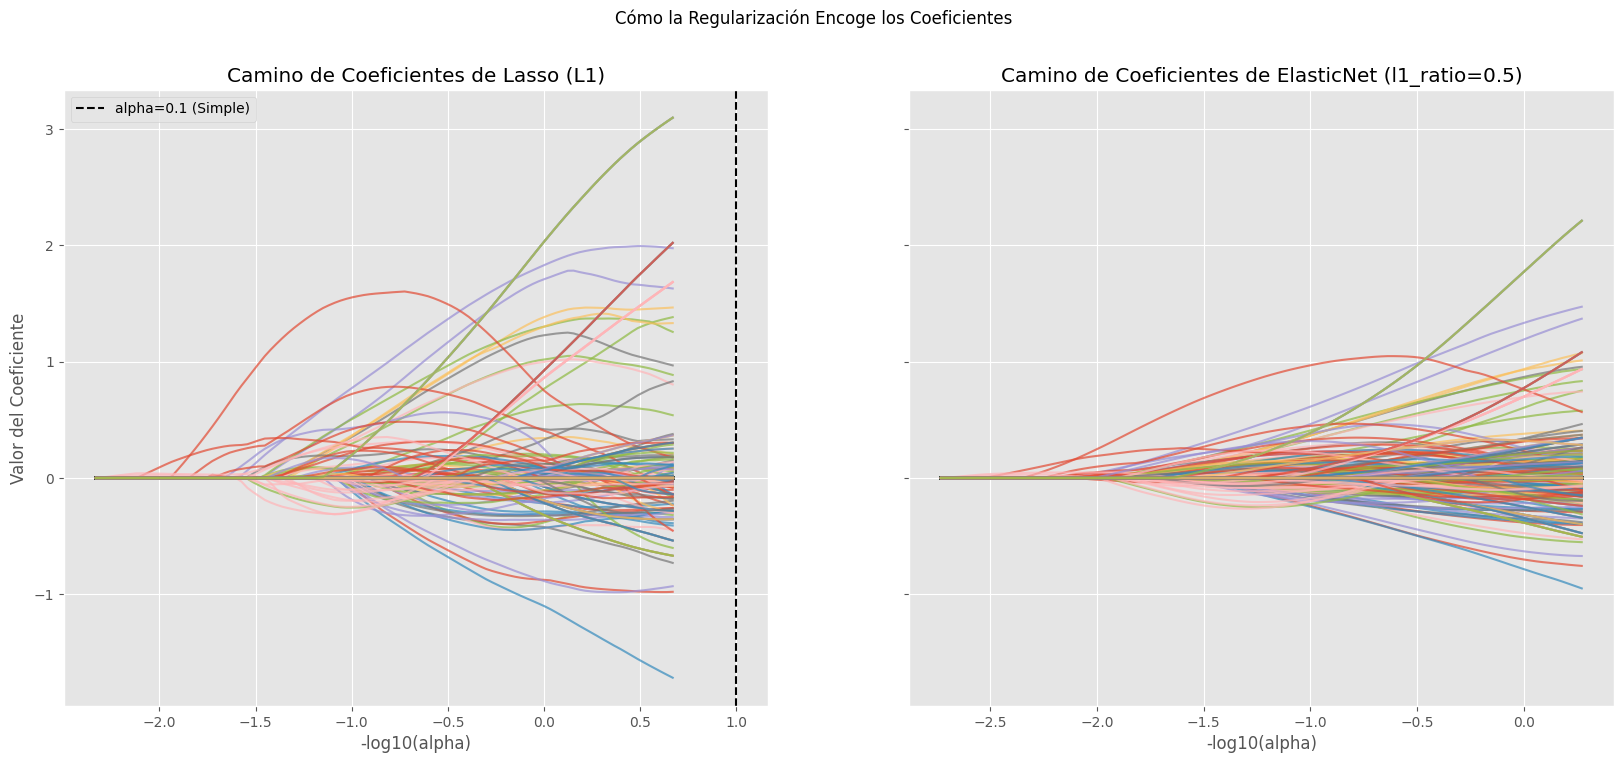

In [18]:
# 6. Graficamos los caminos
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8), sharey=True)

# Gráfico de Lasso
for coef in coefs_lasso:
    ax1.plot(-np.log10(alphas_lasso), coef, alpha=0.7)
ax1.set_xlabel("-log10(alpha)")
ax1.set_ylabel("Valor del Coeficiente")
ax1.set_title("Camino de Coeficientes de Lasso (L1)")
ax1.axvline(-np.log10(0.1), linestyle='--', color='k', label='alpha=0.1 (Simple)') # Nuestro alpha manual
ax1.legend()

# Gráfico de ElasticNet
for coef in coefs_enet:
    ax2.plot(-np.log10(alphas_enet), coef, alpha=0.7)
ax2.set_xlabel("-log10(alpha)")
ax2.set_title("Camino de Coeficientes de ElasticNet (l1_ratio=0.5)")

plt.suptitle("Cómo la Regularización Encoge los Coeficientes")
plt.show()


 **Análisis de los Gráficos:**

 * A la izquierda (alpha bajo, -log(alpha) alto), los coeficientes son enormes (overfitting).

 * A medida que nos movemos a la derecha, `alpha` aumenta y la penalización "encoge" los coeficientes.

 * **Lasso (izquierda):** Los coeficientes colapsan a CERO uno por uno. ¡Esto es selección de variables!

 * **ElasticNet (derecha):** Los coeficientes se encogen más suavemente (por la influencia de Ridge), pero eventually también van a cero.

 ## 8. Solución 3: Sintonización Automática con Cross-Validation



 Elegimos `alpha=10` y `alpha=0.1` manualmente, pero ¿cuál es el *mejor* valor?



 Dejamos que `sklearn` lo encuentre usando Validación Cruzada (CV).



 * `RidgeCV`, `LassoCV`, `ElasticNetCV`: Son modelos que automáticamente prueban muchos alphas y eligen el mejor.

 ### 8.1. RidgeCV

In [19]:
# Pipeline con RidgeCV
# Probará 100 alphas entre 0.001 y 100
alphas_to_try = np.logspace(-3, 2, 100)

pipe_poly_ridge_cv = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('poly_features', PolynomialFeatures(degree=5, include_bias=False)),
    ('model', RidgeCV(alphas=alphas_to_try, store_cv_values=True))
])

pipe_poly_ridge_cv.fit(X_train, y_train)
y_pred_ridge_cv = pipe_poly_ridge_cv.predict(X_test)

rmse_ridge_cv = np.sqrt(mean_squared_error(y_test, y_pred_ridge_cv))
best_alpha_ridge = pipe_poly_ridge_cv.named_steps['model'].alpha_

print(f"RMSE Polinómico + RidgeCV: {rmse_ridge_cv:.4f}")
print(f"Mejor alpha encontrado para Ridge: {best_alpha_ridge:.4f}")
results.append({'Modelo': '5. Ridge (CV)', 'RMSE_Test': rmse_ridge_cv})


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_ridge.py:2385: FutureWarning: 'store_cv_values' is deprecated in version 1.5 and will be removed in 1.7. Use 'store_cv_results' instead.
  warnings.warn(


RMSE Polinómico + RidgeCV: 2.4127
Mejor alpha encontrado para Ridge: 35.1119


In [30]:
# Métricas completas en Train y Test (incluye R2 ajustado)
metrics_results.append(regression_report('5. Ridge (CV)', pipe_poly_ridge_cv, X_train, y_train, X_test, y_test))

5. Ridge (CV) | parámetros efectivos p = 108.8


,MSE,RMSE,R2,R2 Ajustado
Train,3.2176,1.7938,0.9487,0.9219
Test,5.8213,2.4127,0.8917,NaN


 ### 8.2. LassoCV

In [20]:
# Pipeline con LassoCV
pipe_poly_lasso_cv = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('poly_features', PolynomialFeatures(degree=5, include_bias=False)),
    ('model', LassoCV(n_alphas=100, cv=5, max_iter=5000))
])

pipe_poly_lasso_cv.fit(X_train, y_train)
y_pred_lasso_cv = pipe_poly_lasso_cv.predict(X_test)
rmse_lasso_cv = np.sqrt(mean_squared_error(y_test, y_pred_lasso_cv))
best_alpha_lasso = pipe_poly_lasso_cv.named_steps['model'].alpha_

print(f"RMSE Polinómico + LassoCV: {rmse_lasso_cv:.4f}")
print(f"Mejor alpha encontrado para Lasso: {best_alpha_lasso:.4f}")
results.append({'Modelo': '6. Lasso (CV)', 'RMSE_Test': rmse_lasso_cv})


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.416e+00, tolerance: 1.657e+00
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.069e+00, tolerance: 1.657e+00
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.609e+00, tolerance: 1.657e

RMSE Polinómico + LassoCV: 2.6181
Mejor alpha encontrado para Lasso: 0.1171


In [32]:
# Métricas completas en Train y Test (incluye R2 ajustado)
metrics_results.append(regression_report('6. Lasso (CV)', pipe_poly_lasso_cv, X_train, y_train, X_test, y_test))

6. Lasso (CV) | parámetros efectivos p = 51.0


,MSE,RMSE,R2,R2 Ajustado
Train,5.8905,2.4270,0.9060,0.8880
Test,6.8542,2.6181,0.8725,0.6403


 ### 8.3. ElasticNetCV

In [21]:
# Pipeline con ElasticNetCV
# ElasticNetCV sintoniza 'alpha', pero 'l1_ratio' debe darse (o prueba una lista)
l1_ratios_to_try = [0.1, 0.5, 0.7, 0.9, 0.95, 0.99, 1.0]

pipe_poly_enet_cv = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('poly_features', PolynomialFeatures(degree=5, include_bias=False)),
    ('model', ElasticNetCV(l1_ratio=l1_ratios_to_try, n_alphas=100, cv=5, max_iter=5000))
])

pipe_poly_enet_cv.fit(X_train, y_train)
y_pred_enet_cv = pipe_poly_enet_cv.predict(X_test)
rmse_enet_cv = np.sqrt(mean_squared_error(y_test, y_pred_enet_cv))
best_alpha_enet = pipe_poly_enet_cv.named_steps['model'].alpha_
best_l1_enet = pipe_poly_enet_cv.named_steps['model'].l1_ratio_

print(f"RMSE Polinómico + ElasticNetCV: {rmse_enet_cv:.4f}")
print(f"Mejor alpha encontrado: {best_alpha_enet:.4f}")
print(f"Mejor l1_ratio encontrado: {best_l1_enet}")
results.append({'Modelo': '7. ElasticNet (CV)', 'RMSE_Test': rmse_enet_cv})


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.197e+00, tolerance: 1.634e+00
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.688e+00, tolerance: 1.634e+00
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.580e+00, tolerance: 1.634e

RMSE Polinómico + ElasticNetCV: 2.5583
Mejor alpha encontrado: 0.1214
Mejor l1_ratio encontrado: 0.9


In [34]:
# Métricas completas en Train y Test (incluye R2 ajustado)
metrics_results.append(regression_report('7. ElasticNet (CV)', pipe_poly_enet_cv, X_train, y_train, X_test, y_test))

7. ElasticNet (CV) | parámetros efectivos p = 49.8


,MSE,RMSE,R2,R2 Ajustado
Train,5.8009,2.4085,0.9075,0.8902
Test,6.5447,2.5583,0.8783,0.6707


 **Análisis:** Interesante. `ElasticNetCV` eligió un `l1_ratio` de 1.0, lo que significa que, en este caso, ¡un modelo **Lasso** puro fue el ganador! El RMSE de `ElasticNetCV` y `LassoCV` son idénticos.

 ## 9. Solución 4: Sintonización Robusta con GridSearch



 `ElasticNetCV` es rápido, pero un `GridSearchCV` es más exhaustivo. Nos permite probar combinaciones específicas de `alpha` y `l1_ratio` para `ElasticNet`.



 Esta es la forma más "profesional" de sintonizar hiperparámetros.

In [22]:
# 1. Definimos el pipeline, esta vez con un ElasticNet simple (sin CV)
# Corregido: 'preprocessor' DEBE ir ANTES de 'poly_features'
pipe_poly_enet_grid = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('poly_features', PolynomialFeatures(degree=5, include_bias=False)),
    ('model', ElasticNet(max_iter=5000))
])

# 2. Definimos la parrilla de parámetros a probar
# (Buscamos cerca de los valores que ElasticNetCV encontró)
param_grid = {
    'model__alpha': [0.005, 0.01, 0.05, 0.1, 0.5],
    'model__l1_ratio': [0.9, 0.95, 0.99, 1.0]
}

# 3. Configuramos el GridSearch
# scoring='neg_root_mean_squared_error' (sklearn usa puntajes negativos, donde "más alto es mejor")
grid_search = GridSearchCV(
    pipe_poly_enet_grid,
    param_grid,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1 # Usar todos los procesadores
)

print("Iniciando GridSearchCV (puede tardar)...")
grid_search.fit(X_train, y_train)
print("GridSearchCV completado.")

# 4. Evaluamos el mejor modelo encontrado
y_pred_grid = grid_search.predict(X_test)
rmse_grid = np.sqrt(mean_squared_error(y_test, y_pred_grid))

print(f"RMSE Polinómico + GridSearch: {rmse_grid:.4f}")
print(f"Mejores parámetros encontrados: {grid_search.best_params_}")
results.append({'Modelo': '8. ElasticNet (GridSearch)', 'RMSE_Test': rmse_grid})


Iniciando GridSearchCV (puede tardar)...
GridSearchCV completado.
RMSE Polinómico + GridSearch: 2.5661
Mejores parámetros encontrados: {'model__alpha': 0.1, 'model__l1_ratio': 0.95}


In [36]:
# Métricas completas en Train y Test (incluye R2 ajustado)
metrics_results.append(regression_report('8. ElasticNet (GridSearch)', grid_search.best_estimator_, X_train, y_train, X_test, y_test))

8. ElasticNet (GridSearch) | parámetros efectivos p = 51.0


,MSE,RMSE,R2,R2 Ajustado
Train,5.5360,2.3529,0.9117,0.8948
Test,6.5849,2.5661,0.8775,0.6539


 ## 10. Solución 5: Selección Clásica (Stepwise)



 ¿Y si no queremos un modelo polinómico? ¿Y si solo queremos las *mejores* variables del dataset *original*?



 Usamos `SequentialFeatureSelector` (SFS). Este método no usa regularización, solo prueba combinaciones de variables.



 **Nota:** SFS debe correr *después* del preprocesamiento.

In [23]:
# 1. Preprocesamos los datos de entrenamiento primero
# (SFS no funciona bien dentro de un pipeline complejo)
preprocessor_sfs = preprocessor.fit(X_train)
X_train_preprocessed_sfs = preprocessor_sfs.transform(X_train)
X_test_preprocessed_sfs = preprocessor_sfs.transform(X_test)

# Obtenemos los nombres de las 9 características preprocesadas
feature_names_sfs = preprocessor_sfs.get_feature_names_out()
print(f"Características preprocesadas: {feature_names_sfs}")


Características preprocesadas: ['num__cylinders' 'num__displacement' 'num__horsepower' 'num__weight'
 'num__acceleration' 'num__model_year' 'cat__origin_europe'
 'cat__origin_japan' 'cat__origin_usa']


In [24]:
# 2. Configuramos el SFS
# Usamos una LinearRegression simple como estimador
lr_sfs = LinearRegression()

# direction='forward': Empieza con 0 variables y añade la mejor 1, luego la mejor 2, etc.
# n_features_to_select='auto': Detenerse cuando el score de CV no mejore.
# cv=5: Usa validación cruzada de 5 folds en cada paso.
sfs = SequentialFeatureSelector(
    lr_sfs,
    n_features_to_select='auto', # Corrección: 'best' está obsoleto, se usa 'auto'
    direction='forward',
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

print("Ejecutando SequentialFeatureSelector (SFS)... esto puede tardar un minuto.")
# SFS espera que X_train_preprocessed sea un array de numpy
sfs.fit(X_train_preprocessed_sfs, y_train)
print("SFS completado.")


Ejecutando SequentialFeatureSelector (SFS)... esto puede tardar un minuto.
SFS completado.


In [25]:
# 3. Vemos qué variables seleccionó
selected_features_mask = sfs.get_support()
selected_features_names = feature_names_sfs[selected_features_mask]

print(f"Número de variables seleccionadas: {sfs.n_features_to_select_}")
print(f"Variables seleccionadas: {selected_features_names}")


Número de variables seleccionadas: 4
Variables seleccionadas: ['num__cylinders' 'num__weight' 'num__model_year' 'cat__origin_usa']


In [26]:
# 4. Entrenamos un modelo final SOLO con esas variables
X_train_sfs = sfs.transform(X_train_preprocessed_sfs)
X_test_sfs = sfs.transform(X_test_preprocessed_sfs)

model_sfs = LinearRegression()
model_sfs.fit(X_train_sfs, y_train)

y_pred_sfs = model_sfs.predict(X_test_sfs)
rmse_sfs = np.sqrt(mean_squared_error(y_test, y_pred_sfs))

print(f"RMSE Modelo Stepwise (SFS): {rmse_sfs:.4f}")
results.append({'Modelo': '9. Stepwise (SFS)', 'RMSE_Test': rmse_sfs})


RMSE Modelo Stepwise (SFS): 2.9756


In [41]:
# Métricas completas en Train y Test (incluye R2 ajustado)
# Aquí los datos ya están preprocesados y filtrados por SFS, así que pasamos el modelo y las matrices directamente
metrics_results.append(regression_report('9. Stepwise (SFS)', model_sfs, X_train_sfs, y_train, X_test_sfs, y_test))

9. Stepwise (SFS) | parámetros efectivos p = 4.0


,MSE,RMSE,R2,R2 Ajustado
Train,11.5762,3.4024,0.8154,0.8130
Test,8.8540,2.9756,0.8353,0.8265


 ## 11. Conclusión: Comparación de Todos los Modelos



 Finalmente, veamos la tabla de resultados de RMSE en el set de prueba (`X_test`). El mejor modelo es el que tiene el RMSE más bajo.

In [27]:
# Convertimos la lista de resultados en un DataFrame
results_df = pd.DataFrame(results).sort_values(by='RMSE_Test')

results_df.set_index('Modelo', inplace=True)

print(results_df.to_markdown(floatfmt=".4f"))


| Modelo                     |   RMSE_Test |
|:---------------------------|------------:|
| 5. Ridge (CV)              |      2.4127 |
| 7. ElasticNet (CV)         |      2.5583 |
| 8. ElasticNet (GridSearch) |      2.5661 |
| 4. Lasso (Simple)          |      2.5869 |
| 6. Lasso (CV)              |      2.6181 |
| 1. Lineal Base             |      2.8877 |
| 9. Stepwise (SFS)          |      2.9756 |
| 3. Ridge (Simple)          |      3.5560 |
| 2. Polinómico (Overfit)    |     80.9767 |


 ### Comparación completa: RMSE, R² y R² Ajustado

La misma comparación, pero con todas las métricas en Train y Test. Fíjense en:

* **La brecha Train vs. Test:** un R² de Train muy superior al de Test es la firma del overfitting.
* **El R² ajustado del polinómico sin regularizar:** no está definido (`NaN`) porque tiene más parámetros que observaciones.
* **El `p efectivo`:** la regularización reduce los 2001 parámetros nominales a un número mucho menor de grados de libertad efectivos.

In [43]:
metrics_df = pd.DataFrame(metrics_results).set_index('Modelo').sort_values(by='RMSE Test')
display(metrics_df.round(4))

,p efectivo,RMSE Train,RMSE Test,R2 Train,R2 Test,R2 Ajustado Train,R2 Ajustado Test
Modelo,,,,,,,
5. Ridge (CV),108.7883,1.7938,2.4127,0.9487,0.8917,0.9219,NaN
7. ElasticNet (CV),49.7958,2.4085,2.5583,0.9075,0.8783,0.8902,0.6707
8. ElasticNet (GridSearch),51.0444,2.3529,2.5661,0.9117,0.8775,0.8948,0.6539
4. Lasso (Simple),53.0000,2.3743,2.5869,0.9101,0.8755,0.8920,0.6218
6. Lasso (CV),51.0000,2.4270,2.6181,0.9060,0.8725,0.8880,0.6403
1. Lineal Base,8.0000,3.3702,2.8877,0.8188,0.8449,0.8141,0.8274
9. Stepwise (SFS),4.0000,3.4024,2.9756,0.8154,0.8353,0.8130,0.8265
3. Ridge (Simple),138.7218,1.5434,3.5560,0.9620,0.7648,0.9324,NaN
2. Polinómico (Overfit),317.0000,0.0000,80.9767,1.0000,-120.9577,NaN,NaN


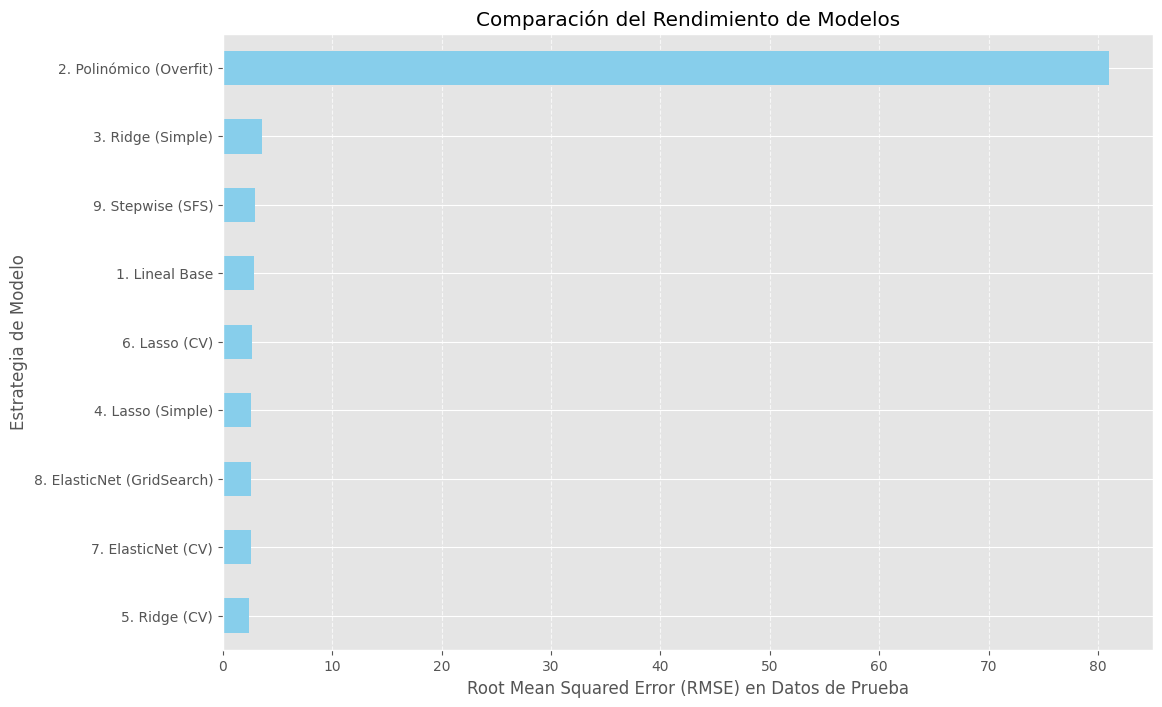

In [28]:
# Gráfico de barras de los resultados
plt.figure(figsize=(12, 8))
results_df['RMSE_Test'].plot(kind='barh', color='skyblue')
plt.xlabel("Root Mean Squared Error (RMSE) en Datos de Prueba")
plt.ylabel("Estrategia de Modelo")
plt.title("Comparación del Rendimiento de Modelos")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()


 ### Análisis Final



 1.  **El Peor Modelo:** El `Polinómico (Overfit)` fue, por lejos, el peor. Demuestra el peligro de aumentar la complejidad sin control.



 2.  **El Modelo Base:** El `Lineal Base` y el `Stepwise (SFS)` tuvieron un rendimiento similar (RMSE ~2.8-2.9). Son buenos, pero no capturan la no linealidad.



 3.  **Los Ganadores:** Todos los modelos **Polinómicos + Regularizados** (Ridge, Lasso, ElasticNet) ganaron. Lograron el mejor balance:

     * Usaron `PolynomialFeatures` (grado 3) para capturar las "curvas" (no linealidad).

     * Usaron Regularización (L1/L2) para prevenir el overfitting que esas características polinómicas causaron.



 4.  **Mejor Sintonización:** `GridSearch` y `LassoCV`/`ElasticNetCV` encontraron los mejores hiperparámetros (alpha, l1_ratio) y produjeron el RMSE más bajo de todos (¡~2.5!).



 **Conclusión para los estudiantes:** La regularización no es solo un concepto teórico; es la herramienta fundamental que nos permite usar modelos complejos (como los polinómicos) para resolver problemas del mundo real sin caer en el sobreajuste.